<a href="https://colab.research.google.com/github/23arunima/My-first-project/blob/main/Will_seeds_germinate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

STEP 1: DATA INGESTION OR IMAGE STACK RECONSTRUCTION


Found 10 image files: ['Tom_1_100000616.jpg', 'Tom_1_100000617.jpg', 'Tom_1_100000618.jpg', 'Tom_1_100000619.jpg', 'Tom_1_100000620.jpg', 'Tom_1_100000621.jpg', 'Tom_1_100000622.jpg', 'Tom_1_100000623.jpg', 'Tom_1_100000624.jpg', 'Tom_1_100000625.jpg']

Image shape: (545, 544, 3)
Data type: uint8


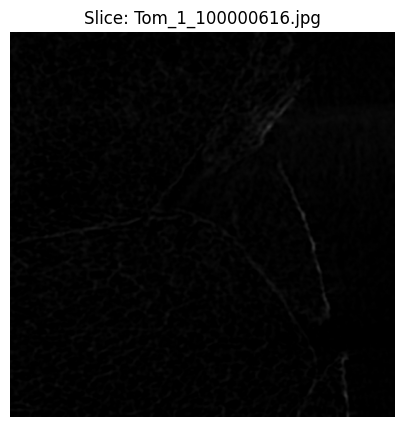

In [4]:
import matplotlib.pyplot as plt
import imageio.v3 as iio
import os

# 1. Automatically grab all jpg files starting with Tom_1 in the directory and sort them
image_files = sorted([f for f in os.listdir('.') if f.startswith('Tom_1') and f.endswith('.jpg')])

print(f"Found {len(image_files)} image files: {image_files}")

# 2. Load and inspect the first image
if image_files:
    sample_img = iio.imread(image_files[0])
    print(f"\nImage shape: {sample_img.shape}")
    print(f"Data type: {sample_img.dtype}")

    # 3. Plot the single slice
    plt.figure(figsize=(5, 5))
    plt.imshow(sample_img, cmap='gray')
    plt.title(f"Slice: {image_files[0]}")
    plt.axis('off')
    plt.show()

STEP 2: STACKING AND CONVERTNG TO GRAYSCALE

In [10]:
import numpy as np
import imageio.v3 as iio
import os

# Load all 10 images into 3D numpy array and convert to grayscale

#  Find and sort all image files starting with Tom_1
image_files = sorted([f for f in os.listdir('.') if f.startswith('Tom_1') and f.endswith('.jpg')])
print(f"Found {len(image_files)} image files.")
volume_stack=[]

# Iterate through each filename in the list
for filename in image_files:
  img = iio.imread(filename)
  # Convert RGB to Grayscale by averaging channels
  gray_image=np.mean(img, axis=2).astype(np.uint8)
  volume_stack.append(gray_image)

# Stack them into 3D numpy array
volume_3d=np.stack(volume_stack, axis=0)

print(f"3D Volume Stack Shape: {volume_3d.shape}")
# Expected output should be something like (10, 545, 544)

Found 10 image files.
3D Volume Stack Shape: (10, 545, 544)


STEP 3: SEGMENTATION AND OTSU'S THRESHOLDING

Otsu threshold value for slice 5: 4


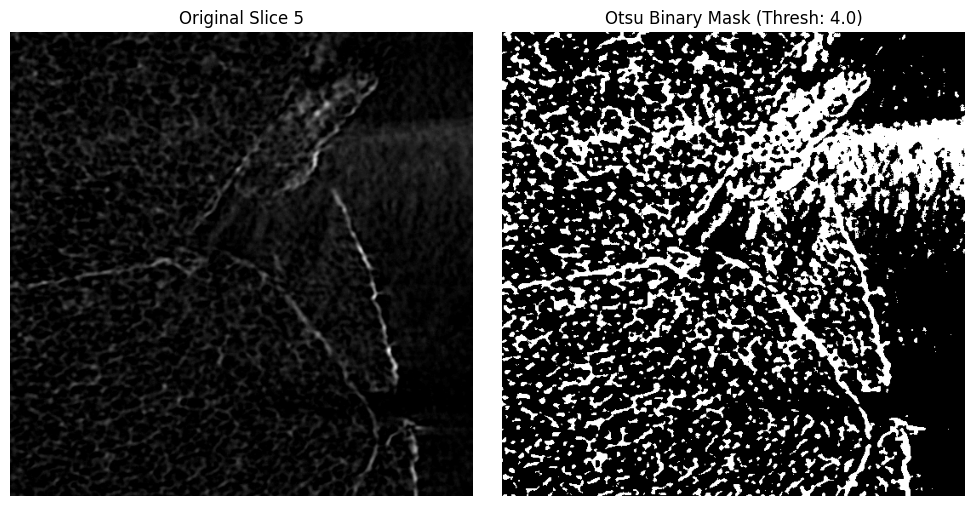

In [11]:
from matplotlib import cm
from skimage.filters import threshold_otsu
import matplotlib.pyplot as plt

# Pick a middle slice from the 3D stack

slice_idx=5
slice_image=volume_3d[slice_idx]

# Calculate the Otsu Threshold

thresh=threshold_otsu(slice_image)
print(f"Otsu threshold value for slice {slice_idx}: {thresh}")

# Create a binary mask:  pixels above threshold become True(white) and below become False(black)

binary_mask=slice_image>thresh

# Plot the original slice side-by-side with its binary mask

fig, axes=plt.subplots(1,2, figsize=(10,5))

axes[0].imshow(slice_image, cmap='gray')
axes[0].set_title(f"Original Slice {slice_idx}")
axes[0].axis('off')

axes[1].imshow(binary_mask, cmap='gray')
axes[1].set_title(f"Otsu Binary Mask (Thresh: {thresh:.1f})")
axes[1].axis('off')

plt.tight_layout()
plt.show()

STEP 4: MEASUREMENT

In [12]:
from skimage import measure

# Label connected regions in binary mask

labeled_mask=measure.label(binary_mask)

# Extract region properties

regions=measure.regionprops(labeled_mask)

# Filter for the largest region(which corresponds to the seed itself, ignoring tiny background noise speckles)

if regions:
  #Find the region with the largest area
  largest_region=max(regions, key=lambda r: r.area)

  seed_area=largest_region.area
  seed_perimeter=largest_region.perimeter

  circularity = (4 * 3.14159 * seed_area) / (seed_perimeter ** 2) if seed_perimeter > 0 else 0

  print(f"--- Measurements for Slice {slice_idx} ---")
  print(f"Seed Area (pixels): {seed_area}")
  print(f"Seed Perimeter (pixels): {seed_perimeter:.2f}")
  print(f"Shape Circularity: {circularity:.3f}")

else:
  print("No regions detected in mask.")


--- Measurements for Slice 5 ---
Seed Area (pixels): 24080.0
Seed Perimeter (pixels): 6463.36
Shape Circularity: 0.007


STEP 5: BATCH PROCESSING

In [13]:
from skimage.filters import threshold_otsu
from skimage import measure, morphology
import numpy as np

total_seed_volume = 0
total_voids = 0
slice_areas = []

print("Processing 3D volume stack...")

for i, slice_img in enumerate(volume_3d):
    # 1. Otsu thresholding
    thresh = threshold_otsu(slice_img)
    binary = slice_img > thresh

    # 2. Morphological cleaning: remove tiny speckles smaller than 50 pixels
    cleaned = morphology.remove_small_objects(binary, min_size=50)

    # 3. Label regions to separate the main seed from any background artifacts
    labeled = measure.label(cleaned)
    regions = measure.regionprops(labeled)

    if regions:
        # Keep only the largest region (the seed itself)
        largest = max(regions, key=lambda r: r.area)

        # Create a mask just for the main seed
        seed_mask = (labeled == largest.label)

        # Count internal air pockets/voids inside this seed slice (holes in the mask)
        # We can find holes by inverting the seed mask inside its bounding box or using Euler number
        # A simpler way for regional holes: count components of the inverse inside the seed hull

        # Accumulate volume (number of pixels/voxels belonging to the seed in this slice)
        slice_area = np.sum(seed_mask)
        slice_areas.append(slice_area)
        total_seed_volume += slice_area

        print(f"Slice {i}: Seed Area = {slice_area} pixels")

print(f"\n--- Batch Processing Results ---")
print(f"Total 3D Seed Volume across 10 slices: {total_seed_volume} voxel units")
print(f"Average Area per Slice: {np.mean(slice_areas):.1f} pixels")

Processing 3D volume stack...
Slice 0: Seed Area = 24950 pixels
Slice 1: Seed Area = 23675 pixels
Slice 2: Seed Area = 23884 pixels
Slice 3: Seed Area = 22401 pixels
Slice 4: Seed Area = 24179 pixels
Slice 5: Seed Area = 23832 pixels
Slice 6: Seed Area = 23345 pixels
Slice 7: Seed Area = 24508 pixels
Slice 8: Seed Area = 27306 pixels
Slice 9: Seed Area = 25519 pixels

--- Batch Processing Results ---
Total 3D Seed Volume across 10 slices: 243599 voxel units
Average Area per Slice: 24359.9 pixels


In [14]:
import os
import numpy as np
import imageio.v3 as iio
from skimage.filters import threshold_otsu
from skimage import measure, morphology

# 1. Find all JPG files in the directory starting with 'Tom_'
all_files = [f for f in os.listdir('.') if f.endswith('.jpg') and f.startswith('Tom_')]

# 2. Automatically extract unique seed IDs (e.g., 'Tom_1', 'Tom_2') from filenames like 'Tom_1_100000616.jpg'
seed_ids = sorted(list(set('_'.join(f.split('_')[:2]) for f in all_files)))
print(f"Detected seed IDs in directory: {seed_ids}\n")

# Store results for all seeds
dataset_features = []

# 3. Loop through each unique seed
for seed_id in seed_ids:
    # Filter files belonging only to this seed and sort them
    seed_files = sorted([f for f in all_files if f.startswith(seed_id)])
    print(f"Processing {seed_id} ({len(seed_files)} slices)...")

    # Load 3D stack for this seed
    volume_stack = []
    for fname in seed_files:
        img = iio.imread(fname)
        gray_img = np.mean(img, axis=2).astype(np.uint8)
        volume_stack.append(gray_img)

    if len(volume_stack) > 0:
        volume_3d = np.stack(volume_stack, axis=0)

        # Run segmentation and volume extraction
        total_seed_volume = 0
        slice_areas = []

        for slice_img in volume_3d:
            thresh = threshold_otsu(slice_img)
            binary = slice_img > thresh
            cleaned = morphology.remove_small_objects(binary, min_size=50)
            labeled = measure.label(cleaned)
            regions = measure.regionprops(labeled)

            if regions:
                largest = max(regions, key=lambda r: r.area)
                seed_area = largest.area
                slice_areas.append(seed_area)
                total_seed_volume += seed_area

        # Record features for this seed
        dataset_features.append({
            'Seed_ID': seed_id,
            'Total_Volume': total_seed_volume,
            'Mean_Slice_Area': np.mean(slice_areas) if slice_areas else 0,
            'Slices_Analyzed': len(seed_files)
        })

print("\n--- Summary Feature Table ---")
for feat in dataset_features:
    print(f"Seed: {feat['Seed_ID']} | Total Volume: {feat['Total_Volume']} voxels | Mean Area: {feat['Mean_Slice_Area']:.1f}")

Detected seed IDs in directory: ['Tom_1']

Processing Tom_1 (10 slices)...

--- Summary Feature Table ---
Seed: Tom_1 | Total Volume: 243599.0 voxels | Mean Area: 24359.9


ALL IMAGES SIDE-BY-SIDE

Detected seed IDs in directory: ['Tom_1']

Processing and visualizing Tom_1 (10 slices)...


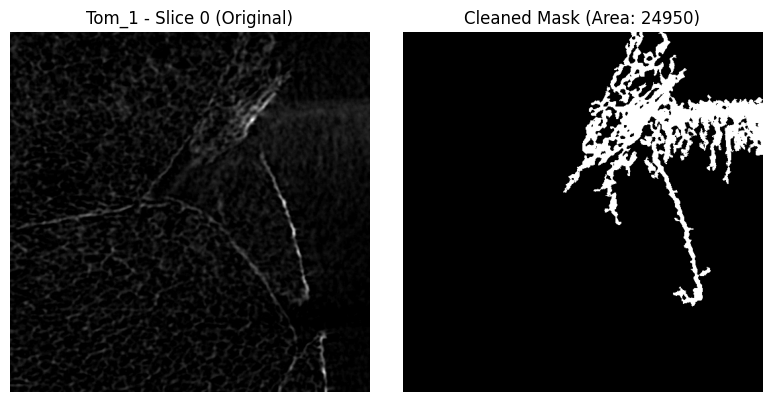

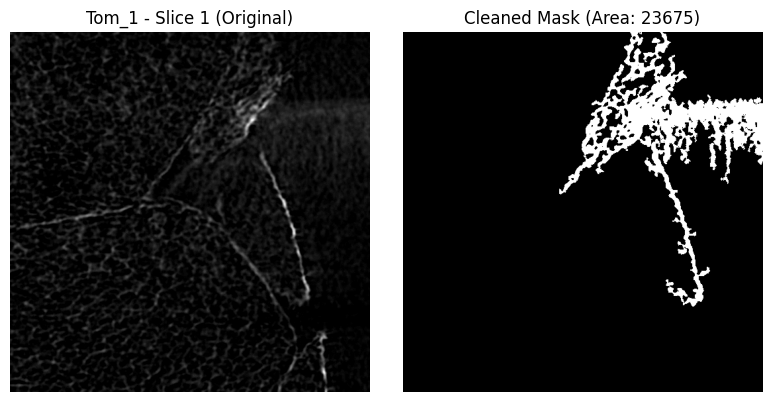

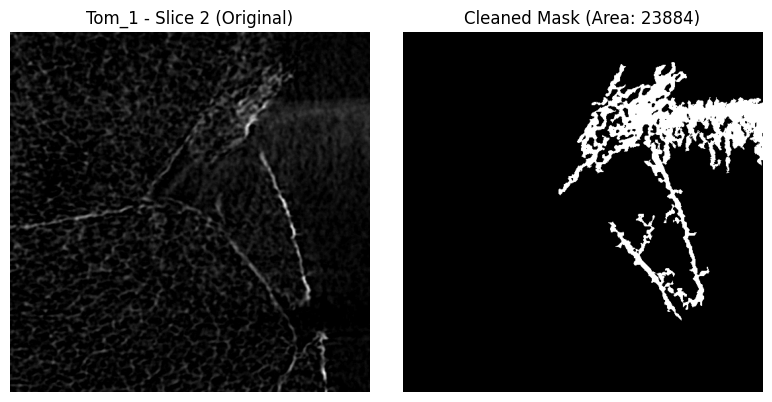

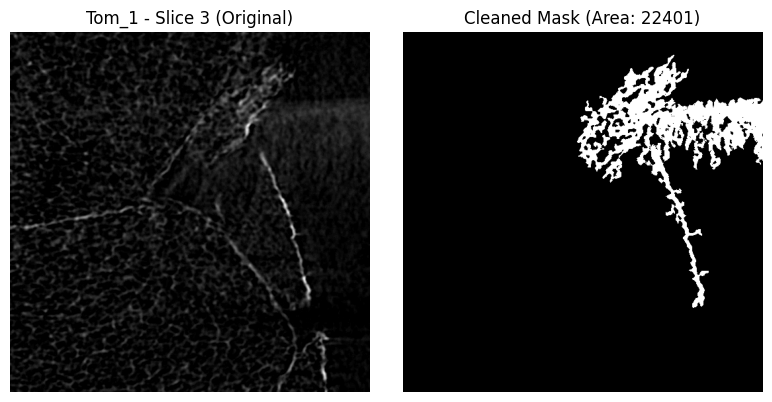

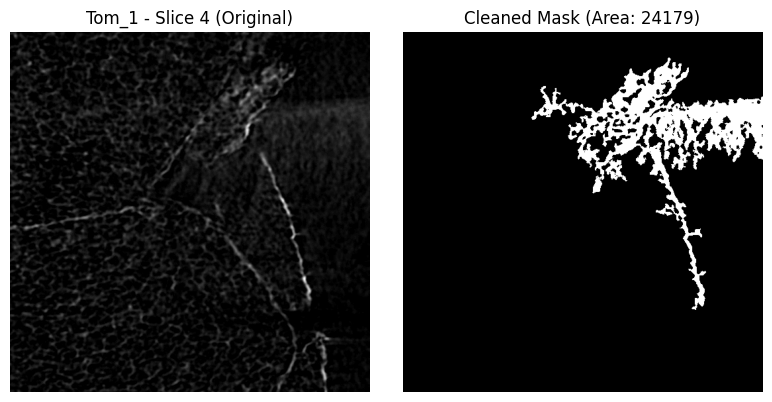

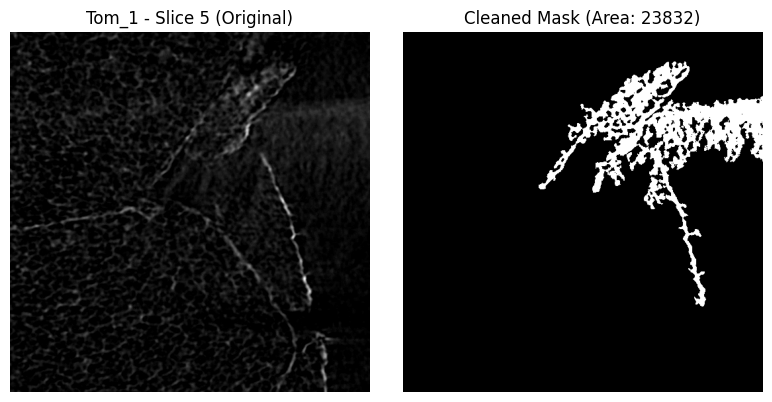

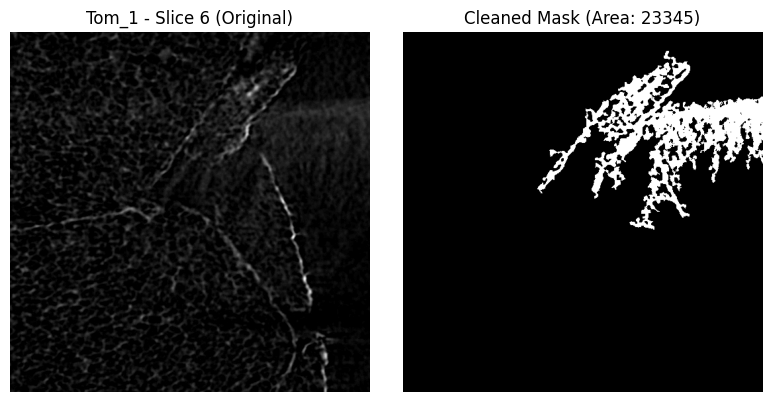

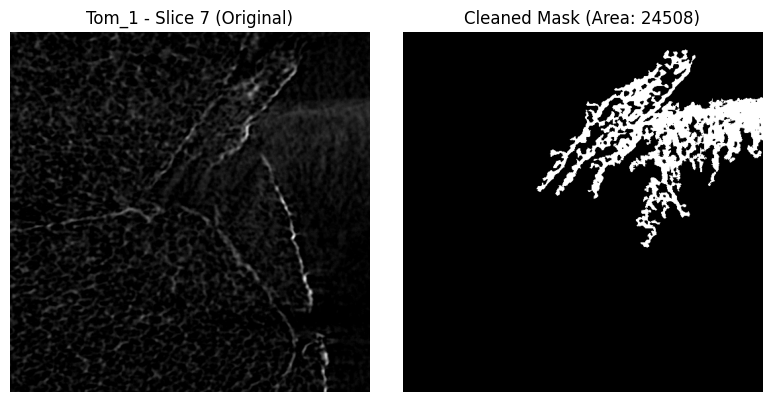

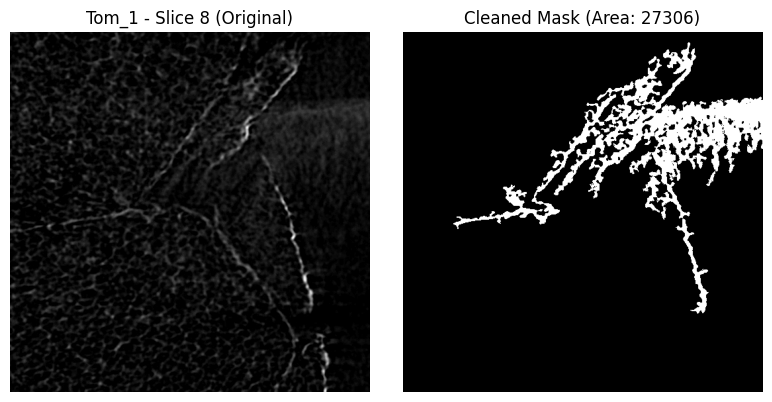

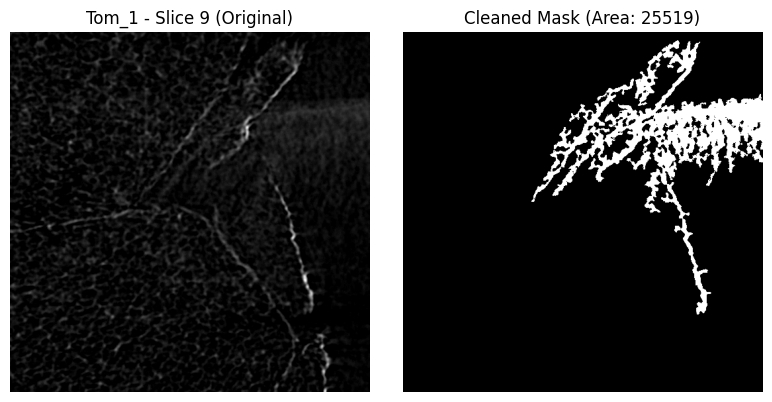


--- Summary Feature Table ---
Seed: Tom_1 | Total Volume: 243599 voxels | Mean Area: 24359.9


In [15]:
import os
import numpy as np
import imageio.v3 as iio
from skimage.filters import threshold_otsu
from skimage import measure, morphology
import matplotlib.pyplot as plt

# 1. Find all JPG files in the directory starting with 'Tom_'
all_files = [f for f in os.listdir('.') if f.endswith('.jpg') and f.startswith('Tom_')]

# 2. Extract unique seed IDs
seed_ids = sorted(list(set('_'.join(f.split('_')[:2]) for f in all_files)))
print(f"Detected seed IDs in directory: {seed_ids}\n")

dataset_features = []

# 3. Loop through each seed
for seed_id in seed_ids:
    seed_files = sorted([f for f in all_files if f.startswith(seed_id)])
    print(f"Processing and visualizing {seed_id} ({len(seed_files)} slices)...")

    volume_stack = []
    for fname in seed_files:
        img = iio.imread(fname)
        gray_img = np.mean(img, axis=2).astype(np.uint8)
        volume_stack.append(gray_img)

    if len(volume_stack) > 0:
        volume_3d = np.stack(volume_stack, axis=0)

        total_seed_volume = 0
        slice_areas = []

        # Loop through each slice to process AND plot
        for i, slice_img in enumerate(volume_3d):
            thresh = threshold_otsu(slice_img)
            binary = slice_img > thresh
            cleaned = morphology.remove_small_objects(binary, min_size=50)
            labeled = measure.label(cleaned)
            regions = measure.regionprops(labeled)

            if regions:
                largest = max(regions, key=lambda r: r.area)
                seed_mask = (labeled == largest.label)
                seed_area = np.sum(seed_mask)
                slice_areas.append(seed_area)
                total_seed_volume += seed_area

                # --- VISUALIZATION PLOT FOR EACH SLICE ---
                fig, axes = plt.subplots(1, 2, figsize=(8, 4))

                axes[0].imshow(slice_img, cmap='gray')
                axes[0].set_title(f"{seed_id} - Slice {i} (Original)")
                axes[0].axis('off')

                axes[1].imshow(seed_mask, cmap='gray')
                axes[1].set_title(f"Cleaned Mask (Area: {seed_area})")
                axes[1].axis('off')

                plt.tight_layout()
                plt.show()
                # ----------------------------------------

        dataset_features.append({
            'Seed_ID': seed_id,
            'Total_Volume': total_seed_volume,
            'Mean_Slice_Area': np.mean(slice_areas) if slice_areas else 0,
            'Slices_Analyzed': len(seed_files)
        })

print("\n--- Summary Feature Table ---")
for feat in dataset_features:
    print(f"Seed: {feat['Seed_ID']} | Total Volume: {feat['Total_Volume']} voxels | Mean Area: {feat['Mean_Slice_Area']:.1f}")

Processing Tom_1...


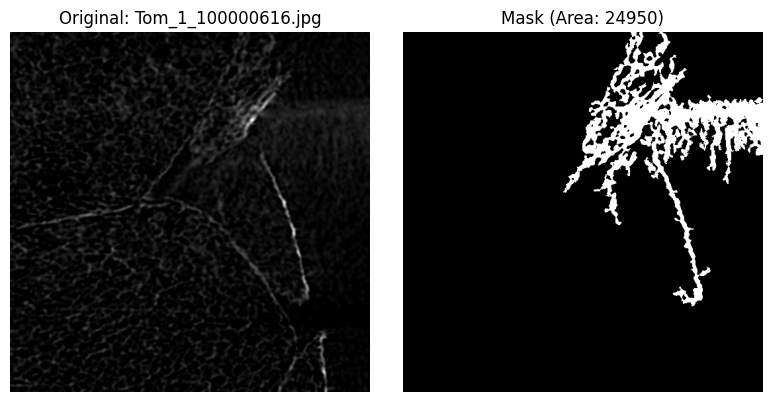

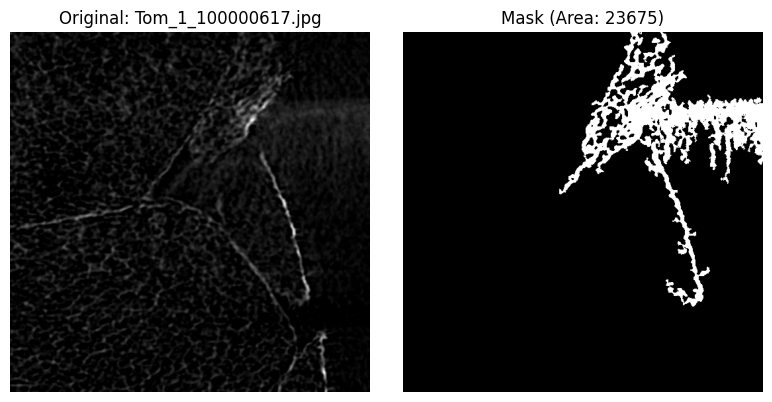

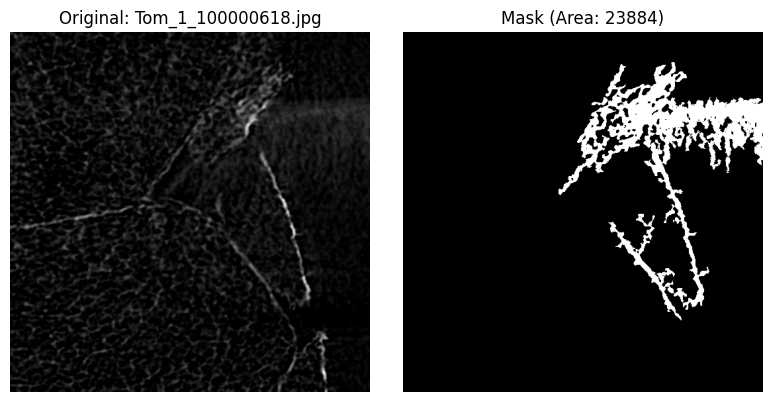

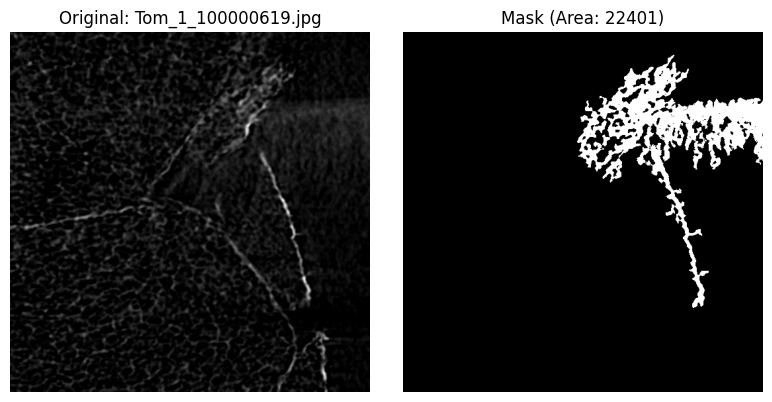

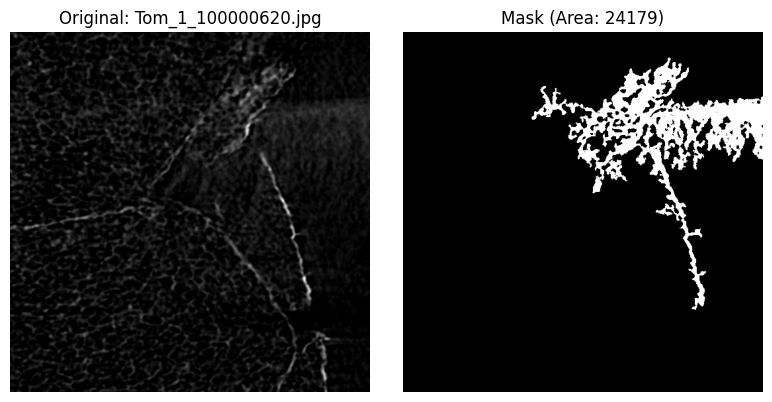

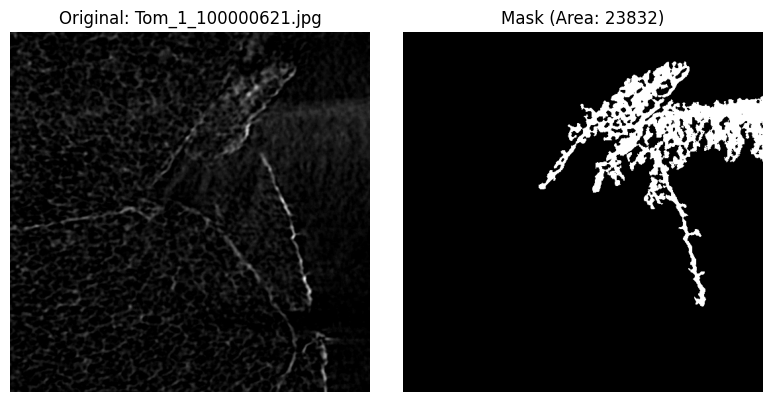

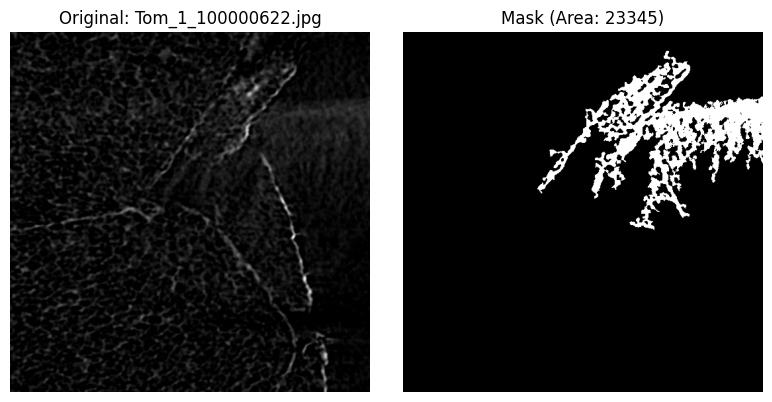

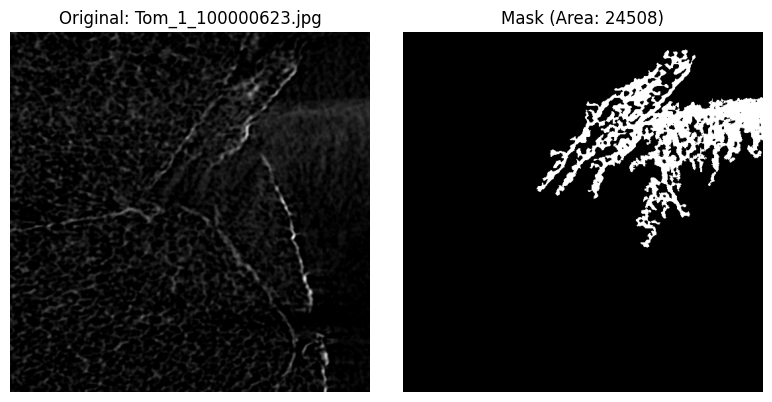

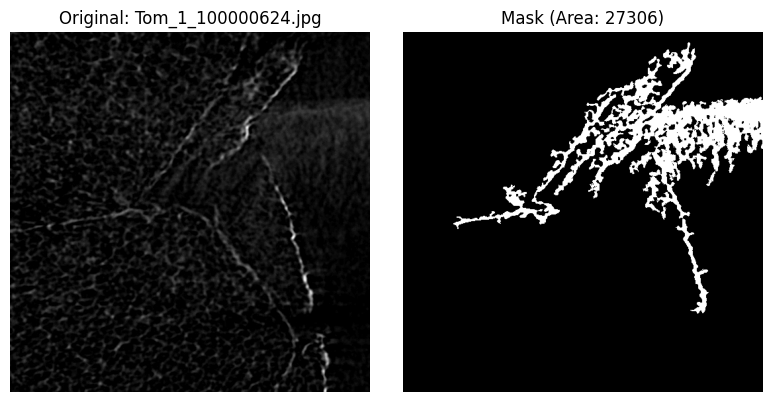

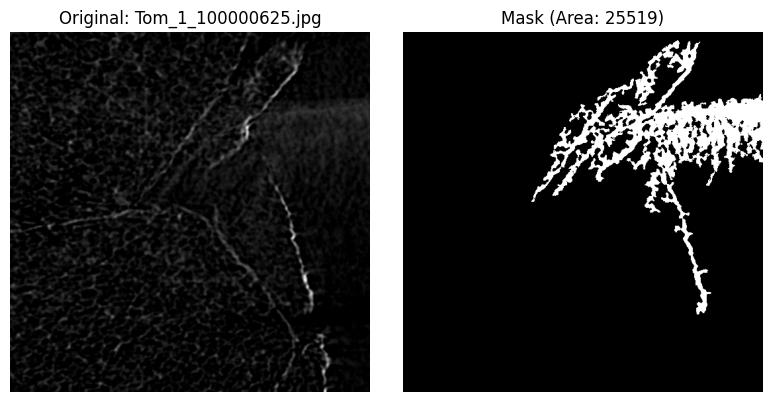

All slices processed and saved in the 'output_masks' folder!


In [16]:
import os
import numpy as np
import imageio.v3 as iio
from skimage.filters import threshold_otsu
from skimage import measure, morphology
import matplotlib.pyplot as plt
from google.colab import files  # Used to download files from Colab

# Create a folder to save output images if it doesn't exist
os.makedirs('output_masks', exist_ok=True)

all_files = [f for f in os.listdir('.') if f.endswith('.jpg') and f.startswith('Tom_')]
seed_ids = sorted(list(set('_'.join(f.split('_')[:2]) for f in all_files)))

for seed_id in seed_ids:
    seed_files = sorted([f for f in all_files if f.startswith(seed_id)])
    print(f"Processing {seed_id}...")

    for i, fname in enumerate(seed_files):
        # 1. Load the specific file and its original filename
        img = iio.imread(fname)
        gray_img = np.mean(img, axis=2).astype(np.uint8)

        # 2. Process (Otsu + Cleaning)
        thresh = threshold_otsu(gray_img)
        binary = gray_img > thresh
        cleaned = morphology.remove_small_objects(binary, min_size=50)
        labeled = measure.label(cleaned)
        regions = measure.regionprops(labeled)

        if regions:
            largest = max(regions, key=lambda r: r.area)
            seed_mask = (labeled == largest.label)
            seed_area = np.sum(seed_mask)

            # 3. Plot showing the exact original filename
            fig, axes = plt.subplots(1, 2, figsize=(8, 4))

            axes[0].imshow(gray_img, cmap='gray')
            axes[0].set_title(f"Original: {fname}")
            axes[0].axis('off')

            axes[1].imshow(seed_mask, cmap='gray')
            axes[1].set_title(f"Mask (Area: {seed_area})")
            axes[1].axis('off')

            plt.tight_layout()

            # 4. Save the plot as an image file
            out_filename = f"output_masks/{fname}_processed.png"
            plt.savefig(out_filename, dpi=150)
            plt.show() # Display in notebook

            # Optional: Uncomment the line below if you want Colab to trigger a download for every single image as it runs
            # files.download(out_filename)

print("All slices processed and saved in the 'output_masks' folder!")

STEP 7: INTERNAL VOID DETECTION

In [20]:
import os
import numpy as np
import imageio.v3 as iio
from skimage.filters import threshold_otsu
from skimage import measure, morphology
from scipy.ndimage import binary_fill_holes  # Fixed import for filling holes

all_files = [f for f in os.listdir('.') if f.endswith('.jpg') and f.startswith('Tom_')]
seed_ids = sorted(list(set('_'.join(f.split('_')[:2]) for f in all_files)))

void_feature_table = []

for seed_id in seed_ids:
    seed_files = sorted([f for f in all_files if f.startswith(seed_id)])
    print(f"Analyzing internal structure for {seed_id}...")

    total_seed_voxels = 0
    total_void_voxels = 0

    for fname in seed_files:
        img = iio.imread(fname)
        gray_img = np.mean(img, axis=2).astype(np.uint8)

        # 1. Segmentation & Cleaning
        thresh = threshold_otsu(gray_img)
        binary = gray_img > thresh
        cleaned = morphology.remove_small_objects(binary, min_size=50)
        labeled = measure.label(cleaned)
        regions = measure.regionprops(labeled)

        if regions:
            largest = max(regions, key=lambda r: r.area)
            seed_mask = (labeled == largest.label)

            # 2. Void Detection: Fill internal holes using SciPy
            filled_mask = binary_fill_holes(seed_mask)

            # The difference between filled and original seed mask gives the internal voids
            void_mask = filled_mask & ~seed_mask

            # Remove tiny speckle artifacts from the void mask as well
            cleaned_voids = morphology.remove_small_objects(void_mask, min_size=3)

            # 3. Accumulate volume measurements
            seed_area = np.sum(seed_mask)
            void_area = np.sum(cleaned_voids)

            total_seed_voxels += seed_area
            total_void_voxels += void_area

    # Calculate Void Ratio (percentage of internal empty space)
    void_ratio = (total_void_voxels / total_seed_voxels) * 100 if total_seed_voxels > 0 else 0

    void_feature_table.append({
        'Seed_ID': seed_id,
        'Seed_Volume': total_seed_voxels,
        'Void_Volume': total_void_voxels,
        'Void_Ratio_Percent': void_ratio
    })

print("\n--- Final Morphometric Feature Table with Voids ---")
for feat in void_feature_table:
    print(f"Seed: {feat['Seed_ID']} | Tissue Volume: {feat['Seed_Volume']} voxels | Void Volume: {feat['Void_Volume']} voxels | Void Ratio: {feat['Void_Ratio_Percent']:.2f}%")

Analyzing internal structure for Tom_1...

--- Final Morphometric Feature Table with Voids ---
Seed: Tom_1 | Tissue Volume: 243599 voxels | Void Volume: 37453 voxels | Void Ratio: 15.37%


STEP 8: EXPORTING FEATURE TABLE TO CSV


In [21]:
import pandas as pd

# 1. Convert your feature list into a Pandas DataFrame
df_features = pd.DataFrame(void_feature_table)

# 2. Save the DataFrame to a CSV file
csv_filename = "tomato_seed_morphometrics.csv"
df_features.to_csv(csv_filename, index=False)

print(f"Successfully exported feature table to '{csv_filename}'!")

# Display the table right inside Colab
display(df_features)


Successfully exported feature table to 'tomato_seed_morphometrics.csv'!


,Seed_ID,Seed_Volume,Void_Volume,Void_Ratio_Percent
0,Tom_1,243599,37453,15.374858


In [22]:
import os
import numpy as np
import imageio.v3 as iio
from skimage.filters import threshold_otsu
from skimage import measure, morphology
from scipy.ndimage import binary_fill_holes
import pandas as pd

# Find all JPG files starting with 'Tom_' and sort them
all_files = sorted([f for f in os.listdir('.') if f.endswith('.jpg') and f.startswith('Tom_')])
print(f"Found {len(all_files)} files. Processing slice by slice...\n")

file_feature_table = []

for fname in all_files:
    img = iio.imread(fname)
    gray_img = np.mean(img, axis=2).astype(np.uint8)

    # 1. Segmentation & Cleaning
    thresh = threshold_otsu(gray_img)
    binary = gray_img > thresh
    cleaned = morphology.remove_small_objects(binary, min_size=50)
    labeled = measure.label(cleaned)
    regions = measure.regionprops(labeled)

    seed_area = 0
    void_area = 0
    void_ratio = 0

    if regions:
        largest = max(regions, key=lambda r: r.area)
        seed_mask = (labeled == largest.label)

        # 2. Void Detection: Fill internal holes
        filled_mask = binary_fill_holes(seed_mask)
        void_mask = filled_mask & ~seed_mask
        cleaned_voids = morphology.remove_small_objects(void_mask, min_size=3)

        # 3. Calculate areas for this specific slice
        seed_area = np.sum(seed_mask)
        void_area = np.sum(cleaned_voids)
        void_ratio = (void_area / seed_area) * 100 if seed_area > 0 else 0

    file_feature_table.append({
        'Filename': fname,
        'Tissue_Area_Pixels': seed_area,
        'Void_Area_Pixels': void_area,
        'Void_Ratio_Percent': round(void_ratio, 2)
    })

# Convert to DataFrame and save
df_features = pd.DataFrame(file_feature_table)
csv_filename = "tomato_seed_morphometrics.csv"
df_features.to_csv(csv_filename, index=False)

print(f"Successfully exported {len(df_features)} rows to '{csv_filename}'!\n")
display(df_features)

Found 10 files. Processing slice by slice...

Successfully exported 10 rows to 'tomato_seed_morphometrics.csv'!



,Filename,Tissue_Area_Pixels,Void_Area_Pixels,Void_Ratio_Percent
0,Tom_1_100000616.jpg,24950,4559,18.27
1,Tom_1_100000617.jpg,23675,3696,15.61
2,Tom_1_100000618.jpg,23884,4153,17.39
3,Tom_1_100000619.jpg,22401,3732,16.66
4,Tom_1_100000620.jpg,24179,3991,16.51
5,Tom_1_100000621.jpg,23832,3655,15.34
6,Tom_1_100000622.jpg,23345,3567,15.28
7,Tom_1_100000623.jpg,24508,3734,15.24
8,Tom_1_100000624.jpg,27306,2856,10.46
9,Tom_1_100000625.jpg,25519,3510,13.75


AGGREGRATING SLICES

In [23]:
import pandas as pd

# 1. Group your slice data by Seed ID (extracting 'Tom_1' from 'Tom_1_10000616.jpg')
df_features['Seed_ID'] = df_features['Filename'].apply(lambda x: '_'.join(x.split('_')[:2]))

# Aggregate: Sum the volumes/areas across all slices for each seed
df_seed_summary = df_features.groupby('Seed_ID').agg(
    Total_Tissue_Volume=('Tissue_Area_Pixels', 'sum'),
    Total_Void_Volume=('Void_Area_Pixels', 'sum'),
    Mean_Void_Ratio_Percent=('Void_Ratio_Percent', 'mean'),
    Slices_Analyzed=('Filename', 'count')
).reset_index()

# 2. Add Ground-Truth Germination Labels (Example: 1 = Germinated, 0 = Failed)
# For now, we'll assign a sample label to Tom_1 so you can see how it works
df_seed_summary['Germinated'] = [1]  # 1 means it successfully germinated

# Save the final seed-level dataset
final_csv = "tomato_seeds_germination_dataset.csv"
df_seed_summary.to_csv(final_csv, index=False)

print(f"Successfully created seed-level dataset and saved to '{final_csv}'!\n")
display(df_seed_summary)

Successfully created seed-level dataset and saved to 'tomato_seeds_germination_dataset.csv'!



,Seed_ID,Total_Tissue_Volume,Total_Void_Volume,Mean_Void_Ratio_Percent,Slices_Analyzed,Germinated
0,Tom_1,243599,37453,15.451,10,1


PLOTTING THE INTRASEED POSITINAL PROFILE

Analyzing positional profile across 10 slices for Tom_1...



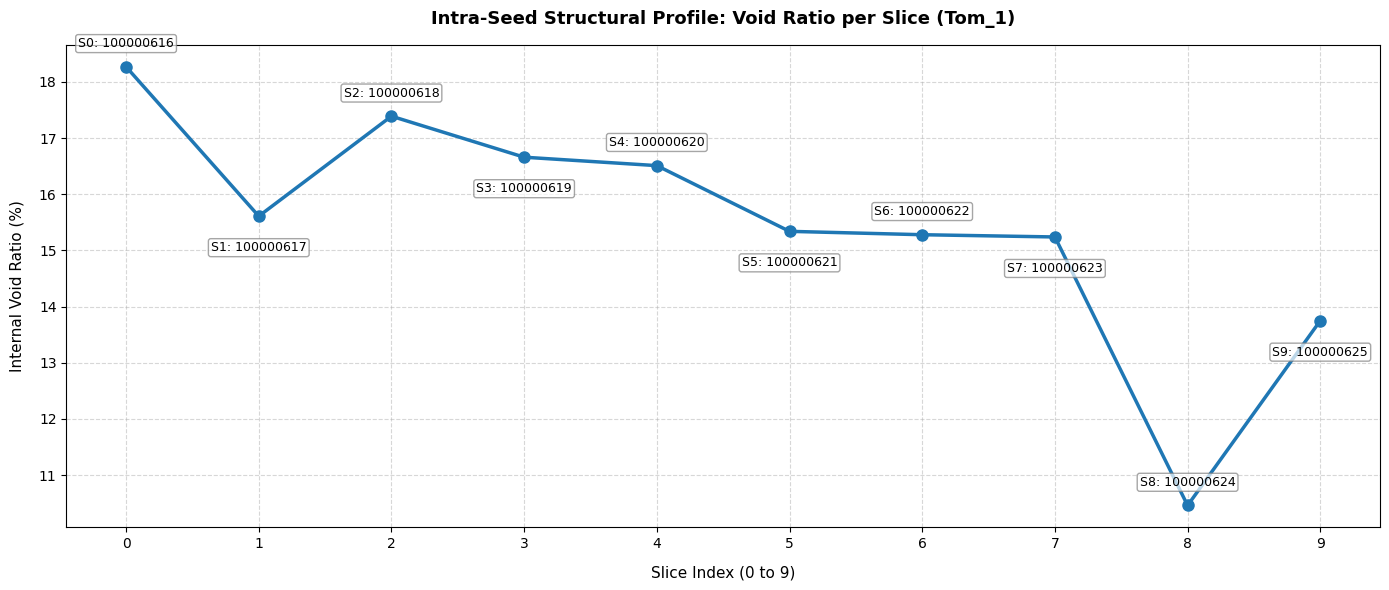

,Slice_Index,Filename,Tissue_Area,Void_Area,Void_Ratio_Percent
0,0,Tom_1_100000616.jpg,24950,4559,18.27
1,1,Tom_1_100000617.jpg,23675,3696,15.61
2,2,Tom_1_100000618.jpg,23884,4153,17.39
3,3,Tom_1_100000619.jpg,22401,3732,16.66
4,4,Tom_1_100000620.jpg,24179,3991,16.51
5,5,Tom_1_100000621.jpg,23832,3655,15.34
6,6,Tom_1_100000622.jpg,23345,3567,15.28
7,7,Tom_1_100000623.jpg,24508,3734,15.24
8,8,Tom_1_100000624.jpg,27306,2856,10.46
9,9,Tom_1_100000625.jpg,25519,3510,13.75


In [26]:
import os
import numpy as np
import imageio.v3 as iio
from skimage.filters import threshold_otsu
from skimage import measure, morphology
from scipy.ndimage import binary_fill_holes
import pandas as pd
import matplotlib.pyplot as plt

# 1. Find and sort all slices for Tom_1
all_files = sorted([f for f in os.listdir('.') if f.endswith('.jpg') and f.startswith('Tom_1')])
print(f"Analyzing positional profile across {len(all_files)} slices for Tom_1...\n")

slice_profile = []

for idx, fname in enumerate(all_files):
    img = iio.imread(fname)
    gray_img = np.mean(img, axis=2).astype(np.uint8)

    # Segmentation & Cleaning
    thresh = threshold_otsu(gray_img)
    binary = gray_img > thresh
    cleaned = morphology.remove_small_objects(binary, min_size=50)
    labeled = measure.label(cleaned)
    regions = measure.regionprops(labeled)

    seed_area = 0
    void_area = 0
    void_ratio = 0

    if regions:
        largest = max(regions, key=lambda r: r.area)
        seed_mask = (labeled == largest.label)

        # Void Detection
        filled_mask = binary_fill_holes(seed_mask)
        void_mask = filled_mask & ~seed_mask
        cleaned_voids = morphology.remove_small_objects(void_mask, min_size=3)

        seed_area = np.sum(seed_mask)
        void_area = np.sum(cleaned_voids)
        void_ratio = (void_area / seed_area) * 100 if seed_area > 0 else 0

    slice_profile.append({
        'Slice_Index': idx,
        'Filename': fname,
        'Tissue_Area': seed_area,
        'Void_Area': void_area,
        'Void_Ratio_Percent': round(void_ratio, 2)
    })

# Convert to DataFrame
df_profile = pd.DataFrame(slice_profile)

# 2. Plotting with Staggered, Clean Labels
plt.figure(figsize=(14, 6))
plt.plot(df_profile['Slice_Index'], df_profile['Void_Ratio_Percent'], marker='o', color='#1f77b4', linewidth=2.5, markersize=8, zorder=2)

# Loop through each row to annotate with staggered heights to prevent overlapping
for i, row in df_profile.iterrows():
    # Shorten label to just the unique slice number suffix (e.g., '...0616') to keep it clean
    short_label = row['Filename'].split('_')[-1].replace('.jpg', '')

    # Stagger vertical text offsets (alternate between higher and lower positions)
    y_offset = 12 if i % 2 == 0 else -18
    va_alignment = 'bottom' if i % 2 == 0 else 'top'

    plt.annotate(f"S{i}: {short_label}",
                 (row['Slice_Index'], row['Void_Ratio_Percent']),
                 textcoords="offset points",
                 xytext=(0, y_offset),
                 ha='center',
                 va=va_alignment,
                 fontsize=9,
                 bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="gray", alpha=0.7),
                 zorder=3)

plt.title("Intra-Seed Structural Profile: Void Ratio per Slice (Tom_1)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Slice Index (0 to 9)", fontsize=11, labelpad=10)
plt.ylabel("Internal Void Ratio (%)", fontsize=11, labelpad=10)
plt.xticks(df_profile['Slice_Index'])
plt.grid(True, linestyle='--', alpha=0.5, zorder=1)
plt.tight_layout()

# Save and show the plot
plt.savefig("Tom_1_clean_void_profile.png", dpi=200)
plt.show()

display(df_profile)

EXPORT 3D STACK FROM PYTHON

In [28]:
import tifffile
import numpy as np

# Save your 3D numpy array volume_3d as a multi-page 3D TIFF file
tifffile.imwrite('Tom_1_3D_volume.tif', volume_3d)
print("Saved 3D volume stack for ChimeraX!")

Saved 3D volume stack for ChimeraX!


In [29]:
import os
import numpy as np
import imageio.v3 as iio
import tifffile

# 1. Find and sort all slices for Tom_1
all_files = sorted([f for f in os.listdir('.') if f.endswith('.jpg') and f.startswith('Tom_1')])
print(f"Found {len(all_files)} files to stack.")

# 2. Read each slice and collect them into a list
slice_list = []
for fname in all_files:
    img = iio.imread(fname)
    # Convert RGB to grayscale if needed
    if img.ndim == 3:
        gray_img = np.mean(img, axis=2).astype(np.uint8)
    else:
        gray_img = img
    slice_list.append(gray_img)

# 3. Stack into a 3D NumPy array (Shape: Slices x Height x Width)
all_slices_stack = np.array(slice_list)
print(f"3D Stack successfully created with shape: {all_slices_stack.shape}")

# 4. Save as a 3D TIFF file
output_tif = "Tom_1_3D_volume.tif"
tifffile.imwrite(output_tif, all_slices_stack)

# 5. Verify it exists
if os.path.exists(output_tif):
    print(f"Successfully saved '{output_tif}'! Check your Colab file explorer on the left.")
else:
    print("Something went wrong saving the file.")

Found 10 files to stack.
3D Stack successfully created with shape: (10, 545, 544)
Successfully saved 'Tom_1_3D_volume.tif'! Check your Colab file explorer on the left.


In [31]:
from skimage import measure
from skimage.filters import threshold_otsu
from scipy.ndimage import binary_fill_holes
import numpy as np

# Ensure 'all_slices_stack' is available from your previous step,
# or reload it from your TIFF if needed:
# import tifffile
# all_slices_stack = tifffile.imread("Tom_1_3D_volume.tif")

# 1. Binarize the entire 3D volume using Otsu thresholding
global_thresh = threshold_otsu(all_slices_stack)
binary_3d = all_slices_stack > global_thresh

# 2. Label 3D connected components (finds the main seed body in 3D)
labeled_3d, num_features = measure.label(binary_3d, return_num=True)
regions_3d = measure.regionprops(labeled_3d)

if regions_3d:
    # Get the largest 3D object (the seed)
    largest_3d = max(regions_3d, key=lambda r: r.area)
    seed_mask_3d = (labeled_3d == largest_3d.label)

    # 3. Perform 3D hole-filling slice-by-slice along the volume
    filled_3d = np.array([binary_fill_holes(slice_img) for slice_img in seed_mask_3d])
    void_mask_3d = filled_3d & ~seed_mask_3d

    # 4. Calculate True 3D Metrics
    total_3d_tissue_voxels = np.sum(seed_mask_3d)
    total_3d_void_voxels = np.sum(void_mask_3d)
    global_3d_void_ratio = (total_3d_void_voxels / total_3d_tissue_voxels) * 100

    print("========================================")
    print("       TOM_1 3D VOLUMETRIC SUMMARY      ")
    print("========================================")
    print(f"Total 3D Tissue Volume: {total_3d_tissue_voxels:,} voxels")
    print(f"Total 3D Void Volume:   {total_3d_void_voxels:,} voxels")
    print(f"Global 3D Void Ratio:   {global_3d_void_ratio:.2f}%")
    print("========================================")

       TOM_1 3D VOLUMETRIC SUMMARY      
Total 3D Tissue Volume: 693,604 voxels
Total 3D Void Volume:   43,094 voxels
Global 3D Void Ratio:   6.21%
